# Cross-paradigm benchmark of game solvers
### Sudoku, Connect Four, Wordle

**Solo project - Symbolic Intelligence (EPITA SCIA)**
Topic L4: *Cross-paradigm benchmark of game solvers*

This notebook systematically compares heterogeneous solving paradigms
(exact search, constraint satisfaction, SAT/SMT, metaheuristics, adversarial
search, information theory) on three different games, using a unified
measurement framework (time, "explored nodes", success rate, memory). The goal
is not to find "the best" solver in the absolute, but to bring out **which
paradigm is structurally suited to which class of problem**.

The source code (the `benchmark/` package) holds all the solver logic; this
notebook only loads the precomputed results (`results/*.csv`, generated by
`uv run python -m benchmark.run_all`) and analyses them. See the repository
README to reproduce the benchmarks.

In [1]:
import sys
sys.path.insert(0, "..") if ".." not in sys.path else None

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

sudoku_df = pd.read_csv("results/sudoku_results.csv")
connect_four_df = pd.read_csv("results/connect_four_results.csv")
wordle_df = pd.read_csv("results/wordle_results.csv")

all_df = pd.concat([sudoku_df, connect_four_df, wordle_df], ignore_index=True)
print(f"{len(sudoku_df)} runs Sudoku, {len(connect_four_df)} runs Connect Four, {len(wordle_df)} runs Wordle")

210 runs Sudoku, 35 runs Connect Four, 120 runs Wordle


## 1. Theoretical framework

### 1.1 Problem classes

| Game | Class | Nature |
|---|---|---|
| **Sudoku** | Constraint satisfaction problem (CSP), NP-complete in its generalised n×n version (Yato & Seta, 2003) | Decision: find **one** valid assignment |
| **Connect Four** | Zero-sum combinatorial game, perfect information | Adversarial search: find the **best move** against an optimal opponent |
| **Wordle** | Sequential search under partial feedback (imperfect information) | Maximise information gain at each step |

These three classes call for very different families of algorithms, which is
precisely the point of the benchmark: we do not compare variants of the same
algorithm, but entire **paradigms**.

### 1.2 Historical background by family

- **Backtracking / Dancing Links**: chronological backtracking is the basic
  method for any CSP. Donald Knuth formalised *Algorithm X* and its *Dancing
  Links* (DLX) data structure in 2000 to efficiently solve the *exact cover*
  problem, of which Sudoku is a special case (a filled cell = one row of an
  exact cover matrix with 4 constraint families: cell, row, column, block).
- **CSP / constraint programming**: beyond naive backtracking, modern CP
  relies on constraint propagation (arc-consistency, AC-3) and global
  constraints such as `AllDifferent`, implemented in industrial solvers like
  **OR-Tools CP-SAT** (Google).
- **SAT/SMT**: founded on the Cook-Levin theorem (NP-completeness of SAT,
  1971) and the DPLL then CDCL algorithms, modern SAT/SMT solving (e.g.
  **Z3**, de Moura & Bjorner, Microsoft Research 2008) turns a logical
  decision problem into a search for a model satisfying first-order
  formulas.
- **Metaheuristics**: genetic algorithms (Holland, 1970s) are inspired by
  natural selection; simulated annealing (Kirkpatrick et al., 1983) is
  inspired by the thermodynamics of metal annealing. Both trade the
  guarantee of optimality for the ability to explore very large search
  spaces with no exploitable structure.
- **Minimax / alpha-beta**: Claude Shannon laid the foundations of tree
  search for games (chess) as early as 1950. Alpha-beta pruning (Knuth &
  Moore, 1975) drastically reduces the explored space without changing the
  result.
- **MCTS**: Monte Carlo Tree Search was formalised by Kocsis & Szepesvari
  (2006) and popularised at large scale by AlphaGo (2016): it replaces a
  hand-written evaluation function with random simulations (rollouts), which
  makes it particularly useful when the heuristic evaluation of a position is
  hard to formalise.
- **Information theory / Wordle**: Shannon entropy (1948) measures the
  uncertainty of a distribution. Choosing the word that maximises the
  expected information gain (popularised for Wordle by 3Blue1Brown in 2022)
  is a direct application of this framework to a sequential guessing game.

### 1.3 When to use which paradigm?

This is the central question of the benchmark (objectives 4 and 5 of the
topic) - it is answered with data at the end of this notebook (section 5),
but the theoretical intuition is:

- **SAT/SMT** excels at proving the satisfiability or unsatisfiability of a
  set of logical constraints (decision), with a strong correctness guarantee.
- **CP/CP-SAT** is preferable as soon as there is an objective to optimise
  (not just a feasible solution), thanks to very expressive global
  constraints.
- **Backtracking/DLX** remains relevant when the structure of the problem
  (exact cover) allows a very efficient search without needing a generic
  solver.
- **Metaheuristics** (GA, simulated annealing) are useful when the search
  space is too large or too unstructured for an exact method, at the price
  of no guarantee of finding a solution.
- **Minimax/alpha-beta** suits perfect-information games with a reasonable
  branching factor and a good evaluation heuristic.
- **MCTS** is preferable when the branching factor is large or the
  evaluation heuristic is hard to write by hand.
- **Bayesian / entropy approaches** suit sequential search problems under
  partial feedback (imperfect information).

## 2. Sudoku

**7 paradigms** compared: naive backtracking, backtracking + MRV (Minimum
Remaining Values), Dancing Links (Algorithm X), genetic algorithm, simulated
annealing, CP-SAT (OR-Tools), SMT (Z3).

**Instances**: 10 grids per difficulty level (`easy` = Easy51,
`medium_hard` = top95, `diabolical` = hardest11), i.e. 30 grids x 7
paradigms = 210 runs. Each run is capped at 2 minutes; beyond that it is
counted as a failure (timeout).

**Normalisation of "explored nodes"** (to keep in mind when reading the
table):
- backtracking / DLX / CP-SAT / SMT: number of decisions/assignments tried
- genetic / simulated annealing: number of cost function evaluations
  (row/column conflicts)

These numbers are **not comparable in absolute value across families**
(a CP-SAT "node" is very different work from a backtracking "node"): they
mainly serve to compare algorithms of the same family with each other
(e.g. backtracking vs backtracking+MRV).

In [2]:
summary_sudoku = (
    sudoku_df.groupby("paradigm")
    .agg(
        success_rate=("success", "mean"),
        mean_time_s=("time_seconds", "mean"),
        mean_nodes=("nodes_explored", "mean"),
        std_time_s=("time_seconds", "std"),
    )
    .sort_values("mean_time_s")
)
summary_sudoku

,success_rate,mean_time_s,mean_nodes,std_time_s
paradigm,,,,
dancing_links,1.000000,0.005812,217.333333,0.003845
cp_sat,1.000000,0.010419,55.466667,0.004254
smt,1.000000,0.328192,5936.866667,0.282580
backtracking,0.733333,0.521801,804024.866667,0.535564
backtracking_mrv,1.000000,1.235931,91682.100000,3.979713
simulated_annealing,0.200000,2.197853,248836.000000,0.958378
genetic,0.000000,9.409902,400200.000000,1.291180


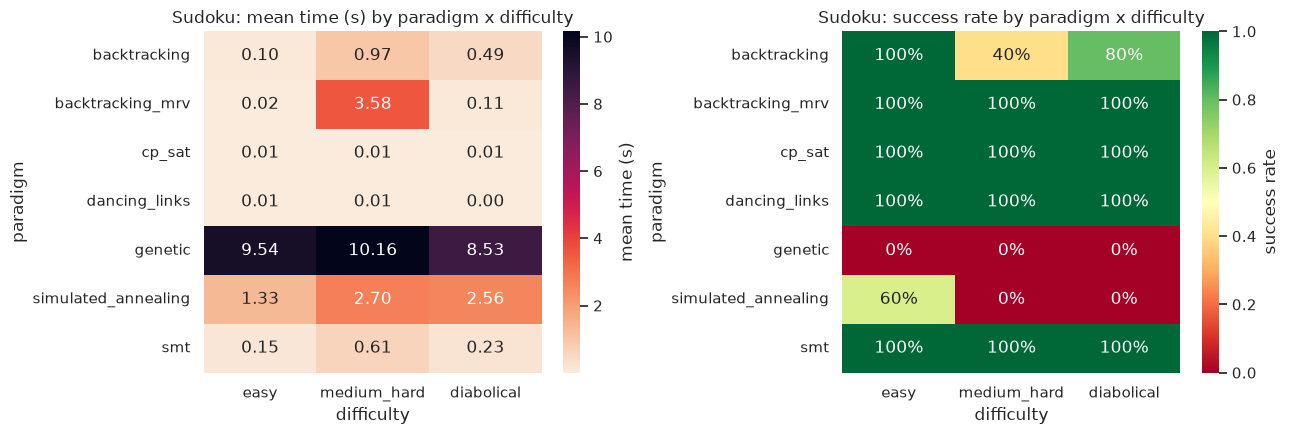

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pivot_time = sudoku_df.pivot_table(index="paradigm", columns="difficulty", values="time_seconds", aggfunc="mean")
pivot_time = pivot_time[["easy", "medium_hard", "diabolical"]]
sns.heatmap(pivot_time, annot=True, fmt=".2f", cmap="rocket_r", ax=axes[0], cbar_kws={"label": "mean time (s)"})
axes[0].set_title("Sudoku: mean time (s) by paradigm x difficulty")

pivot_success = sudoku_df.pivot_table(index="paradigm", columns="difficulty", values="success", aggfunc="mean")
pivot_success = pivot_success[["easy", "medium_hard", "diabolical"]]
sns.heatmap(pivot_success, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "success rate"})
axes[1].set_title("Sudoku: success rate by paradigm x difficulty")

plt.tight_layout()
plt.savefig("results/figures/sudoku_heatmaps.png", dpi=120)
plt.show()

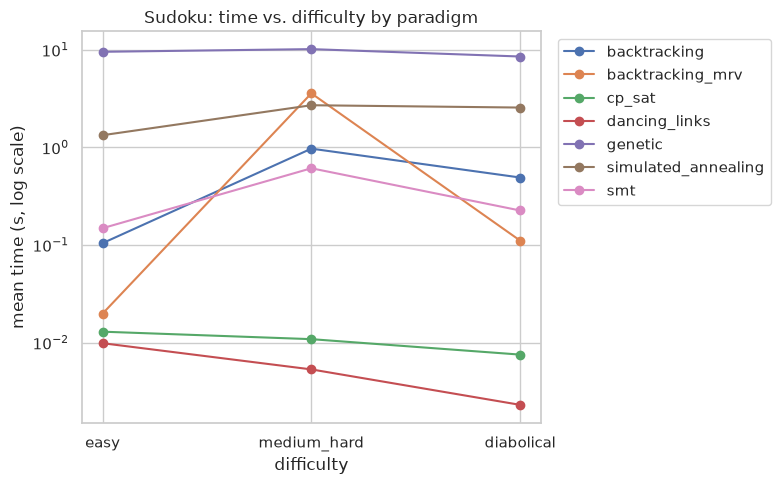

In [4]:
difficulty_order = {"easy": 0, "medium_hard": 1, "diabolical": 2}
plot_df = sudoku_df.copy()
plot_df["difficulty_rank"] = plot_df["difficulty"].map(difficulty_order)

fig, ax = plt.subplots(figsize=(8, 5))
for paradigm, group in plot_df.groupby("paradigm"):
    means = group.groupby("difficulty_rank")["time_seconds"].mean()
    ax.plot(means.index, means.values, marker="o", label=paradigm)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["easy", "medium_hard", "diabolical"])
ax.set_yscale("log")
ax.set_xlabel("difficulty")
ax.set_ylabel("mean time (s, log scale)")
ax.set_title("Sudoku: time vs. difficulty by paradigm")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("results/figures/sudoku_time_vs_difficulty.png", dpi=120)
plt.show()

**Reading the Sudoku results:**

- The **modern exact solvers** (Dancing Links, CP-SAT, SMT,
  backtracking+MRV) reach ~100% success, including on the "diabolical"
  grids. This is a direct manifestation of decades of algorithmic
  optimisation on CSPs.
- **CP-SAT solves Sudoku with 0 explored nodes for 29 grids out of 30** (1664 nodes for a single grid, mean 55): constraint propagation of the global
  `AllDifferent` constraint alone is enough to determine the solution
  without search/branching in almost all cases. This is a striking empirical
  result that illustrates the power of modern constraint propagation compared
  with naive backtracking - even the "exploration" has disappeared.
- **Naive backtracking** (with no variable-selection heuristic) fails on
  some instances: the node budget or the 2-minute timeout is exceeded on
  adversarial grids, concretely illustrating why a variable-selection
  heuristic (MRV) and/or constraint propagation are indispensable as soon as
  the problem becomes combinatorially hard.
- The **metaheuristics (GA, simulated annealing) have a low success rate**
  on our instances, even "easy" ones. This is not a bug: it is a
  well-documented property in the literature - a "pure" GA on a block-based
  representation converges very poorly on Sudoku without additional
  techniques (hybridisation with hill-climbing, frequent restarts, specific
  crossover operators). Simulated annealing does somewhat better because it
  performs fine local search, but remains sensitive to the cooling schedule.
  This result illustrates the structural limit of general-purpose
  metaheuristics on a highly constrained problem: they do not exploit the
  combinatorial structure of the problem the way a dedicated CSP/SAT solver
  does.

## 3. Connect Four

**4 algorithms** implemented from scratch (without any external game
library): minimax, minimax + alpha-beta pruning (with move ordering by
proximity to the centre), MCTS (UCB1, random rollout), and a greedy baseline
(1-move lookahead, no opponent model).

**Comparison protocol**: rather than an all-against-all tournament (hard to
interpret across heterogeneous paradigms), each tested algorithm plays one
**complete game** against a fixed reference opponent: alpha-beta at depth 4.
"Success" = the tested algorithm wins the game.

**Difficulty parameter**: search depth for minimax (1 to 6 - beyond that the
absence of pruning makes a complete game impractical in reasonable time) and
alpha-beta (1 to 9). MCTS has no fixed depth: it is given a proportional
simulation budget (`50 x depth`), which allows a comparison at "equivalent
computational effort" rather than at identical depth - an important nuance
because MCTS is *anytime* (it can be stopped at any moment) whereas
minimax/alpha-beta are not.

In [5]:
summary_c4 = (
    connect_four_df.groupby("paradigm")
    .agg(
        win_rate=("success", "mean"),
        mean_time_s=("time_seconds", "mean"),
        mean_nodes=("nodes_explored", "mean"),
        mean_plies=("solution_quality", "mean"),
    )
    .sort_values("win_rate", ascending=False)
)
summary_c4

,win_rate,mean_time_s,mean_nodes,mean_plies
paradigm,,,,
alpha_beta,0.666667,10.463255,140674.666667,30.666667
minimax,0.666667,12.364522,143713.000000,32.666667
baseline,0.000000,0.331514,49.000000,14.000000
mcts,0.000000,1.720004,2355.000000,16.600000


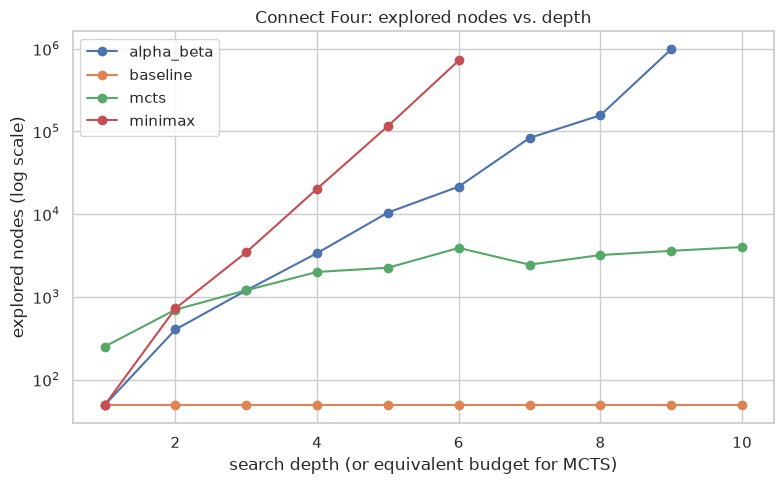

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for paradigm, group in connect_four_df.groupby("paradigm"):
    g = group.sort_values("difficulty")
    ax.plot(g["difficulty"], g["nodes_explored"], marker="o", label=paradigm)
ax.set_yscale("log")
ax.set_xlabel("search depth (or equivalent budget for MCTS)")
ax.set_ylabel("explored nodes (log scale)")
ax.set_title("Connect Four: explored nodes vs. depth")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/connect_four_nodes_vs_depth.png", dpi=120)
plt.show()

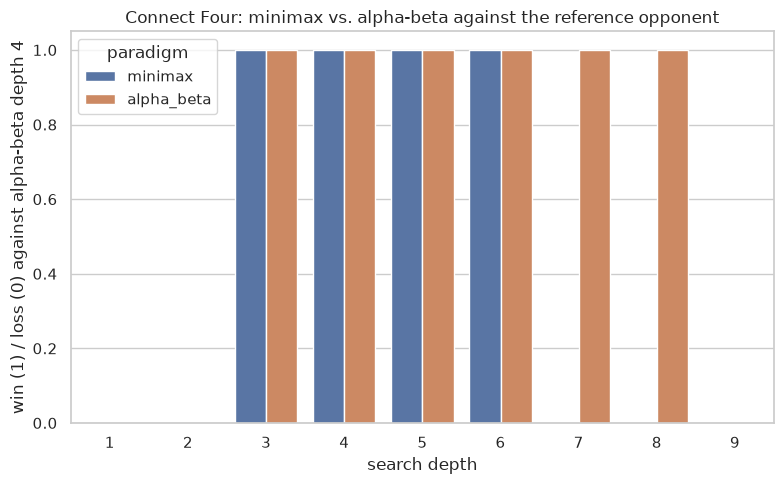

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
win_by_depth = connect_four_df[connect_four_df["paradigm"].isin(["minimax", "alpha_beta"])]
sns.barplot(data=win_by_depth, x="difficulty", y="success", hue="paradigm", ax=ax)
ax.set_ylabel("win (1) / loss (0) against alpha-beta depth 4")
ax.set_xlabel("search depth")
ax.set_title("Connect Four: minimax vs. alpha-beta against the reference opponent")
plt.tight_layout()
plt.savefig("results/figures/connect_four_winrate.png", dpi=120)
plt.show()

**Reading the Connect Four results:**

- The number of nodes explored by **minimax grows much faster** than that of
  **alpha-beta** at equal depth: this is a direct demonstration of the
  contribution of pruning (for an identical game result when compared at the
  same depth), and the reason why we had to limit minimax to depth 6 whereas
  alpha-beta holds up to 9 in reasonable time.
- The **greedy baseline systematically loses** against the reference
  opponent (depth 4): without anticipating the opponent's replies, it falls
  into simple tactical traps - useful as a low-end reference point.
- **MCTS with a modest simulation budget** generally remains weaker than
  alpha-beta at equivalent depth on Connect Four: this is consistent with the
  literature (Connect Four has a low branching factor - 7 - where a good
  hand-written heuristic like ours is very effective; MCTS shines mainly when
  the space is too large or the heuristic hard to define, which is not the
  case here).

## 4. Wordle

**3 solvers** compared: simple Bayesian elimination (candidate chosen at
random among the compatible ones), Shannon entropy maximisation (popularised
by 3Blue1Brown), and a CSP model via OR-Tools CP-SAT (consistent with the
approach used for Sudoku).

**Instances**: 10 target words per length (5, 6, 7, 8 letters), drawn from a
standard English word list (`english-words`, filtered and frozen in
`data/wordle/` for reproducibility - see README). "Success" = word found in
at most 6 attempts.

In [8]:
summary_wordle = (
    wordle_df.groupby("paradigm")
    .agg(
        success_rate=("success", "mean"),
        mean_attempts=("solution_quality", "mean"),
        mean_time_s=("time_seconds", "mean"),
        mean_candidates_evaluated=("nodes_explored", "mean"),
    )
    .sort_values("mean_attempts")
)
summary_wordle

,success_rate,mean_attempts,mean_time_s,mean_candidates_evaluated
paradigm,,,,
entropy,1.0,2.725,6.493110,2019.475
bayesian_elimination,1.0,3.300,0.003298,2081.025
csp,1.0,3.400,0.110733,0.000


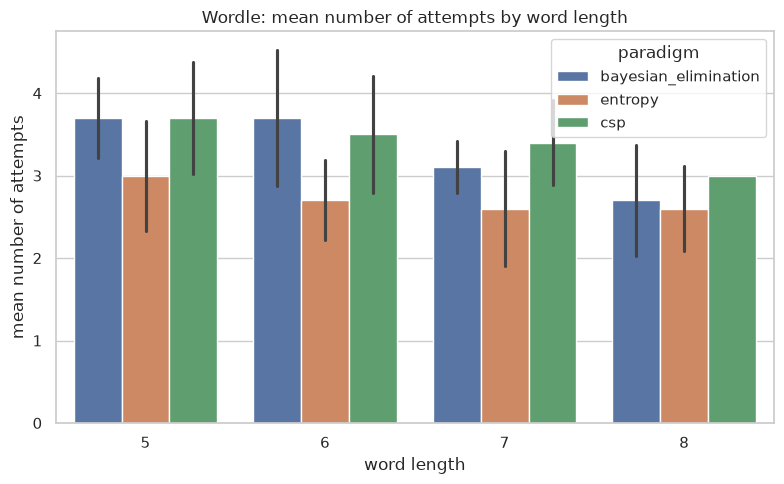

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=wordle_df, x="difficulty", y="solution_quality", hue="paradigm", ax=ax, errorbar="sd")
ax.set_xlabel("word length")
ax.set_ylabel("mean number of attempts")
ax.set_title("Wordle: mean number of attempts by word length")
plt.tight_layout()
plt.savefig("results/figures/wordle_attempts.png", dpi=120)
plt.show()

**Reading the Wordle results:**

- The **entropy maximisation** solver finds the word in fewer attempts on
  average than the "naive" Bayesian elimination (which picks its next guess
  at random among the compatible candidates): this is the direct empirical
  demonstration of the value of choosing the move that **maximises the
  expected information gain**, rather than an arbitrarily valid move.
- The **CSP** solver (searching for a compatible word via CP-SAT
  `AllowedAssignments`) systematically explores 0 nodes (40 games out of 40),
  as is almost always the case for Sudoku CP-SAT - once again constraint
  propagation alone is enough to find a satisfying assignment, without
  branching. Note: our CSP encoding does not maximise information gain (it
  returns any compatible word), which explains why it does not
  systematically beat entropy in number of attempts despite a similar
  computational cost per move.

## 5. Cross-cutting analysis and paradigm selection guide

### 5.1 Cost per node by paradigm

The chart below relates the number of explored nodes to the total time, all
games combined. The slope of each point cloud gives an idea of the **mean
cost per node** for each paradigm: a CP-SAT or SMT node is much richer work
(global constraint propagation, SMT theory) than a naive backtracking node,
but there are generally far fewer of them.

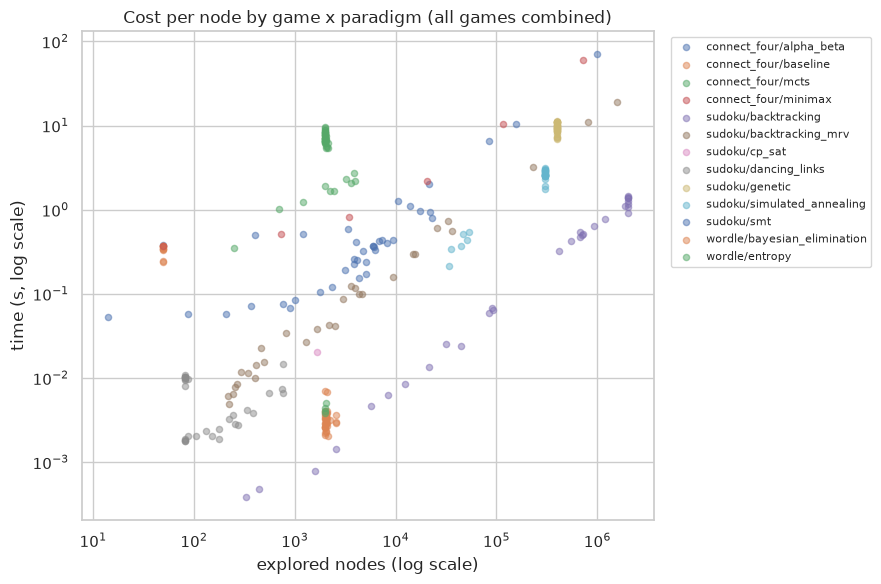

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
for (game, paradigm), group in all_df.groupby(["game", "paradigm"]):
    valid = group[(group["nodes_explored"] > 0) & (group["time_seconds"] > 0)]
    if len(valid) == 0:
        continue
    ax.scatter(valid["nodes_explored"], valid["time_seconds"], alpha=0.5, label=f"{game}/{paradigm}", s=20)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("explored nodes (log scale)")
ax.set_ylabel("time (s, log scale)")
ax.set_title("Cost per node by game x paradigm (all games combined)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("results/figures/nodes_vs_time_all.png", dpi=120)
plt.show()

### 5.2 Global comparison table

In [11]:
global_summary = (
    all_df.groupby(["game", "paradigm"])
    .agg(
        success_rate=("success", "mean"),
        mean_time_s=("time_seconds", "mean"),
        mean_nodes=("nodes_explored", "mean"),
    )
    .round(4)
)
global_summary

success_rate  mean_time_s   mean_nodes
game         paradigm                                                    
connect_four alpha_beta                  0.6667      10.4633  140674.6667
             baseline                    0.0000       0.3315      49.0000
             mcts                        0.0000       1.7200    2355.0000
             minimax                     0.6667      12.3645  143713.0000
sudoku       backtracking                0.7333       0.5218  804024.8667
             backtracking_mrv            1.0000       1.2359   91682.1000
             cp_sat                      1.0000       0.0104      55.4667
             dancing_links               1.0000       0.0058     217.3333
             genetic                     0.0000       9.4099  400200.0000
             simulated_annealing         0.2000       2.1979  248836.0000
             smt                         1.0000       0.3282    5936.8667
wordle       bayesian_elimination        1.0000       0.0033    2081.0250
             csp                         1.0000       0.1107       0.0000
             entropy                     1.0000       6.4931    2019.4750

### 5.3 Paradigm selection guide

To summarise all the empirical results and the theoretical discussion of
section 1:

| Problem class | Recommended paradigm | Rationale |
|---|---|---|
| Pure constraint satisfaction (find **one** valid solution) | **CP-SAT / SMT** | Very effective global constraint propagation; on Wordle-CSP, 0 search nodes in all our measurements; on Sudoku, 0 nodes for 29 grids out of 30 - propagation alone almost always suffices |
| Problem with exploitable *exact cover* structure | **Dancing Links** | Very low practical complexity when the combinatorial structure fits (Sudoku), with no dependence on an external generic solver |
| Huge, weakly structured search space, approximate solution acceptable | **Metaheuristics (GA, simulated annealing)** | Only viable options if no exact method scales - but our results show they often fail where a dedicated CSP solver systematically succeeds: use only if no exploitable structure exists |
| Perfect-information game, low branching factor, good heuristic available | **Minimax + alpha-beta** | Alpha-beta pruning gives a gain of several orders of magnitude in explored nodes for an identical result compared with naive minimax |
| Perfect-information game, high branching factor or heuristic hard to write | **MCTS** | Avoids the need for a hand-written evaluation function; flexible computational budget (anytime) |
| Sequential search under partial feedback (imperfect information) | **Entropy maximisation** | Directly exploits information theory to minimise the expected number of steps, empirically measured as superior to an arbitrary choice among valid candidates |

### 5.4 Limitations and future work

- **Sudoku metaheuristics**: our GA/simulated annealing implementations are
  deliberately simple (no advanced crossover operators, no hybridisation with
  heavy local search). A fuller memetic GA would be a possible improvement,
  but the gap with CSP solvers would most likely remain very large.
- **Solvers not implemented**: Choco (Java/JPype bridge, flagged as unstable
  in the CoursIA ecosystem), neural network and LLM for Sudoku were not
  implemented in this project (outside a reasonable scope for a solo
  project), but represent additional interesting paradigms to compare (in
  particular training cost vs. inference cost, absent from all the symbolic
  paradigms studied here).
- **Connect Four**: our MCTS uses a purely random rollout (no informed
  simulation policy); an MCTS with heuristic rollouts or an evaluation
  function at the end of the simulation would probably be more competitive
  against alpha-beta at equal computational budget.
- **Wordle**: the CSP solver could be extended to maximise information gain
  *in the form of constraints* (instead of returning an arbitrary compatible
  word), which would bring it closer to the performance of the entropy
  solver while remaining within the CP paradigm.